# Selección de modelos OLS

## 1. Configuración
Preparar las funciones compartidas y la conexión al experimento existente `Modelos Propiedades_Usadas`.

In [1]:
from pathlib import Path
import json
import sys
import shutil
import numpy as np
from IPython.display import display, Markdown, Image
from statsmodels.regression.linear_model import OLSResults
# Configuración única del paquete para ejecutar desde la raíz o el notebook.
carpeta_paquete = next((c for p in (Path.cwd(), *Path.cwd().parents)
    for c in (p, p / "Ventas/Propiedades_Usadas")
    if (c / "scripts/__init__.py").is_file()), None)
if carpeta_paquete is None:
    raise RuntimeError("Ejecutar el notebook dentro del proyecto Moscow_EDA.")
if str(carpeta_paquete) not in sys.path:
    sys.path.insert(0, str(carpeta_paquete))
from scripts.contrato_datasets import (
    CARPETA_PROYECTO, DATA_DIR as DATOS_PROYECTO, DATASETS, SCRIPTS_DIR, RAIZ as raiz,
)
base = CARPETA_PROYECTO
from scripts import baseline_ols as b
from scripts import seleccion_modelos as s
from scripts.diagnosticos_residuales import ARCHIVOS


from scripts.almacenamiento_mlflow import SesionTemporal, leer_json, RUN_TRANSFORMACION
sesion = SesionTemporal()
with sesion.paso():
    out = sesion.carpeta("forward")


## 2. Carga de datos
Utilizar exclusivamente el CSV transformado de Train, con `ln(Target)`, intercepto y las exclusiones `to_center_km`, `living_area` y `rooms`.

In [2]:
with sesion.paso():
    X, y, contexto_train = b.cargar_train(base)
    X = X.drop(columns=list(s.EXCLUIDAS))


## 3. Recuperación de métricas desde MLflow
Recuperar el Run Forward terminado y su referencia histórica; verificar el mismo Train y los criterios de cálculo registrados.

In [3]:
%%capture
with sesion.paso():
    cliente = b.conectar(base.parents[1])
    forward = s.recuperar_experimento(cliente, nombre=s.NOMBRE_RUN,
        etiquetas={'dataset_sha256': contexto_train['dataset_sha256']})
    referencia = s.recuperar_experimento(cliente, nombre=s.REFERENCIA,
        run_id=forward['params']['reference_run_id'],
        parametros={'target_transform': 'ln(Target)', 'inverse_transform': 'exp',
            'bias_correction': 'none', 'intercepto': 'True', 'train_fraction': '1.0',
            'n_train': len(y), 'excluded_predictors': ','.join(s.EXCLUIDAS),
            'aic_bic_convention': 'statsmodels_gaussian_log_RUB_k_rank'},
        etiquetas={'dataset_sha256': contexto_train['dataset_sha256']})
    estado = s.restaurar_forward(cliente, forward, out, contexto_train, referencia)


## 4. Agrupación de características
Reconstruir y verificar los bloques completos mediante el linaje exportado. El mapeo de columnas permanece en los artefactos de reproducibilidad.

In [4]:
with sesion.paso():
    resumen = leer_json(cliente, RUN_TRANSFORMACION, 'transformacion/resumen_final.json')
    grupos = s.grupos_caracteristicas(X.columns, resumen)
    assert grupos == estado['grupos_caracteristicas']['grupos']


## 5. Forward Selection por grupos
Recuperar la búsqueda ya ejecutada con mejora mínima del 0,5 %, máximo de 12 características y partición fija 80/20. Conservar el subconjunto y el modelo definitivo registrados.

In [5]:
with sesion.paso():
    seleccion = estado['seleccion']
    seleccionadas = seleccion['seleccionadas']
    columnas = s.columnas_grupos(grupos, seleccionadas)
    assert columnas == estado['contexto']['predictoras']
    assert len(seleccionadas) <= int(forward['params']['max_features']) <= 12
    with np.load(out / 'particion_interna.npz') as particion:
        fit, val = particion['fit'], particion['validation']
    modelo = OLSResults.load(out / 'modelo_statsmodels.pkl')
    caracteristicas_md = s.resumen_caracteristicas(seleccionadas, grupos, modelo)
    _ = (out / 'caracteristicas_seleccionadas.md').write_text(caracteristicas_md, encoding='utf-8')
    display(Markdown(caracteristicas_md))


| Orden | Característica seleccionada | Cantidad de predictores |
|---|---|---|
| 1 | `district` | 128 |
| 2 | `total_area` | 1 |
| 3 | `renovation` | 3 |
| 4 | `date_posted_dt` | 1 |
| 5 | `building_type` | 5 |
| 6 | `metro_distance_min` | 1 |
| 7 | `metro_distance_type` | 1 |
| Total | 7 características | 140 predictores |

## 6. Evaluación del modelo
Comparar las métricas de Train del modelo definitivo con las métricas históricas recuperadas desde MLflow. Mantener separado el RMSE de validación interna; las ausencias se muestran como `N/D`.

In [6]:
with sesion.paso():
    metricas = estado['metricas']
    assert modelo.nobs == len(y) == metricas['train_n_obs']
    comparacion_md = s.tabla_comparativa(referencia['metrics'], metricas)
    assert comparacion_md == (out / 'comparacion_referencia.md').read_text(encoding='utf-8')
    display(Markdown(comparacion_md))


| Métrica | OLS_05_Log_Sin_rooms | Forward_01_Log_Grupos | Δ |
|---|---|---|---|
| R² (ln(RUB)) | 0.9550461329765028 | 0.9535767773806381 | -0.0014693555958646964 |
| R² ajustado (ln(RUB)) | 0.9548392517349442 | 0.9534050348875294 | -0.0014342168474148487 |
| MAE (ln(RUB)) | 0.09397764063347668 | 0.09548260169146015 | 0.0015049610579834782 |
| RMSE (ln(RUB)) | 0.11826166956163559 | 0.1201788710987355 | 0.0019172015370999135 |
| RSS (ln(RUB)) | 531.2374813654084 | 548.6014328485893 | 17.363951483180927 |
| MSE (ln(RUB)) | 0.013985822487505486 | 0.014442961058566484 | 0.00045713857106099813 |
| AIC (ln(RUB)) | -54036.78552484463 | -52883.10480890103 | 1153.6807159435994 |
| BIC (ln(RUB)) | -52541.42447279798 | -51678.27104696631 | 863.1534258316751 |
| F-statistic (ln(RUB)) | 4616.3979188323565 | 5552.363658639613 | 935.9657398072568 |
| Probabilidad F-statistic (ln(RUB)) | 0.0 | 0.0 | 0.0 |
| n_obs | 37984.0 | 37984.0 | 0.0 |
| Cantidad de predictores | 174.0 | 140.0 | -34.0 |
| n_parameters_effective | 175.0 | 141.0 | -34.0 |
| n_coefficients | 175.0 | 141.0 | -34.0 |
| df_model | 174.0 | 140.0 | -34.0 |
| df_resid | 37809.0 | 37843.0 | 34.0 |
| log_likelihood (ln(RUB)) | 27193.392762422314 | 26582.552404450515 | -610.8403579717997 |
| Durbin-Watson (ln(RUB)) | 1.79863136465654 | 1.7997379301297685 | 0.0011065654732285157 |
| n_coefficients_p_gt_005 (ln(RUB)) | 20.0 | 4.0 | -16.0 |
| n_coefficients_p_undefined (ln(RUB)) | 0.0 | 0.0 | 0.0 |
| Condition Number | 13583.004658488904 | 13160.606929511569 | -422.39772897733565 |
| rank_deficiency | 0.0 | 0.0 | 0.0 |
| jarque_bera (ln(RUB)) | 212.75283395237017 | 297.74674309965445 | 84.99390914728428 |
| jarque_bera_pvalue (ln(RUB)) | 6.328621212723001e-47 | 2.2136870964588015e-65 | -6.328621212723001e-47 |
| skewness (ln(RUB)) | -0.17819107513464388 | -0.20221783738082585 | -0.02402676224618197 |
| kurtosis (ln(RUB)) | 3.08613114796366 | 3.1567213199003024 | 0.07059017193664241 |
| omnibus (ln(RUB)) | 208.90761150582992 | 287.57947982513156 | 78.67186831930164 |
| omnibus_pvalue (ln(RUB)) | 4.328012911598663e-46 | 3.57198315107597e-63 | -4.328012911598663e-46 |
| VIF máximo | 10.635811414220557 | 8.553944860139906 | -2.0818665540806514 |
| VIF promedio | 2.0681713132370767 | 2.031640323596522 | -0.03653098964055479 |
| Cantidad VIF > 5 | 2.0 | 1.0 | -1.0 |
| Cantidad VIF > 10 | 1.0 | 0.0 | -1.0 |
| vif_infinite_count | 0.0 | 0.0 | 0.0 |
| vif_undefined_count | 0.0 | 0.0 | 0.0 |
| bp_lm (ln(RUB)) | 1101.4863201926644 | 768.1881354835621 | -333.2981847091023 |
| bp_lm_pvalue (ln(RUB)) | 1.6833367762487824e-134 | 2.336959491146487e-87 | 2.336959491146487e-87 |
| bp_f (ln(RUB)) | 6.489399909082759 | 5.579530035116568 | -0.9098698739661906 |
| bp_f_pvalue (ln(RUB)) | 5.239080209821676e-137 | 1.6853410264462636e-88 | 1.6853410264462636e-88 |
| R² (precio original) | 0.926508311457361 | 0.9243969318325274 | -0.0021113796248336536 |
| R² ajustado (precio original) | 0.9261700969103902 | 0.9241172386384506 | -0.0020528582719395727 |
| MAE (precio original) | 1100634.4604864721 | 1116830.7647747274 | 16196.304288255284 |
| RMSE (precio original) | 1586808.7385496828 | 1609441.4455567568 | 22632.70700707403 |
| MAPE (precio original) | 9.475418273576777 | 9.633475459651416 | 0.1580571860746396 |
| RSS (precio original) | 9.564226757246635e+16 | 9.839002230541446e+16 | 2747754732948112.0 |
| MSE (precio original) | 2517961972737.6357 | 2590301766675.823 | 72339793938.1875 |
| Cantidad de características | N/D | 7.0 | N/D |

## 7. Diagnóstico de residuos
Mostrar los tres diagnósticos registrados del modelo definitivo, calculados sobre los residuos en escala logarítmica.

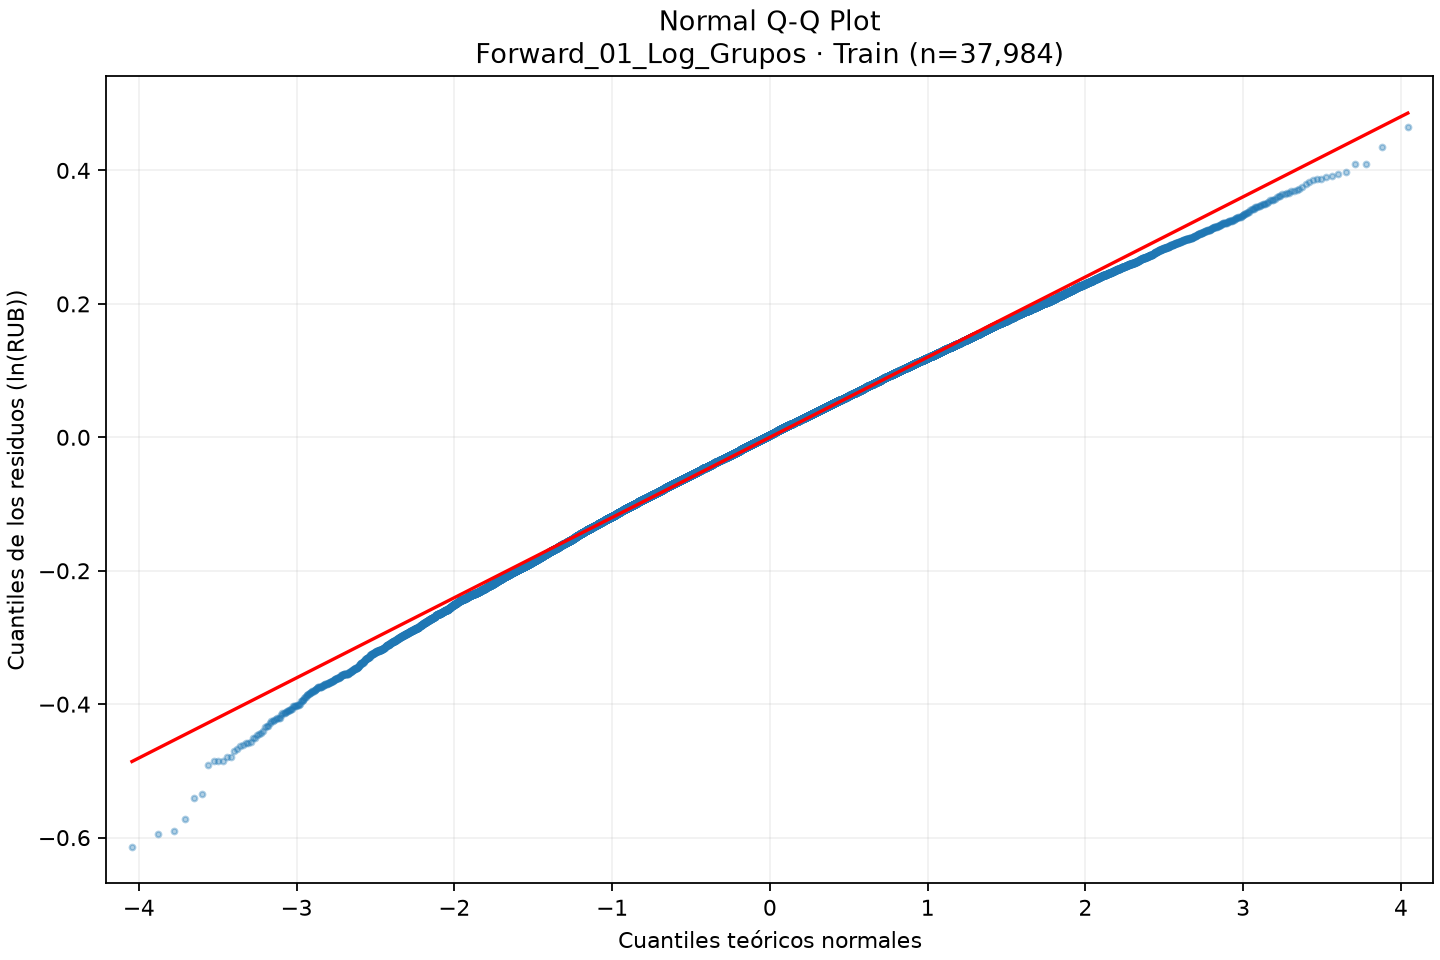

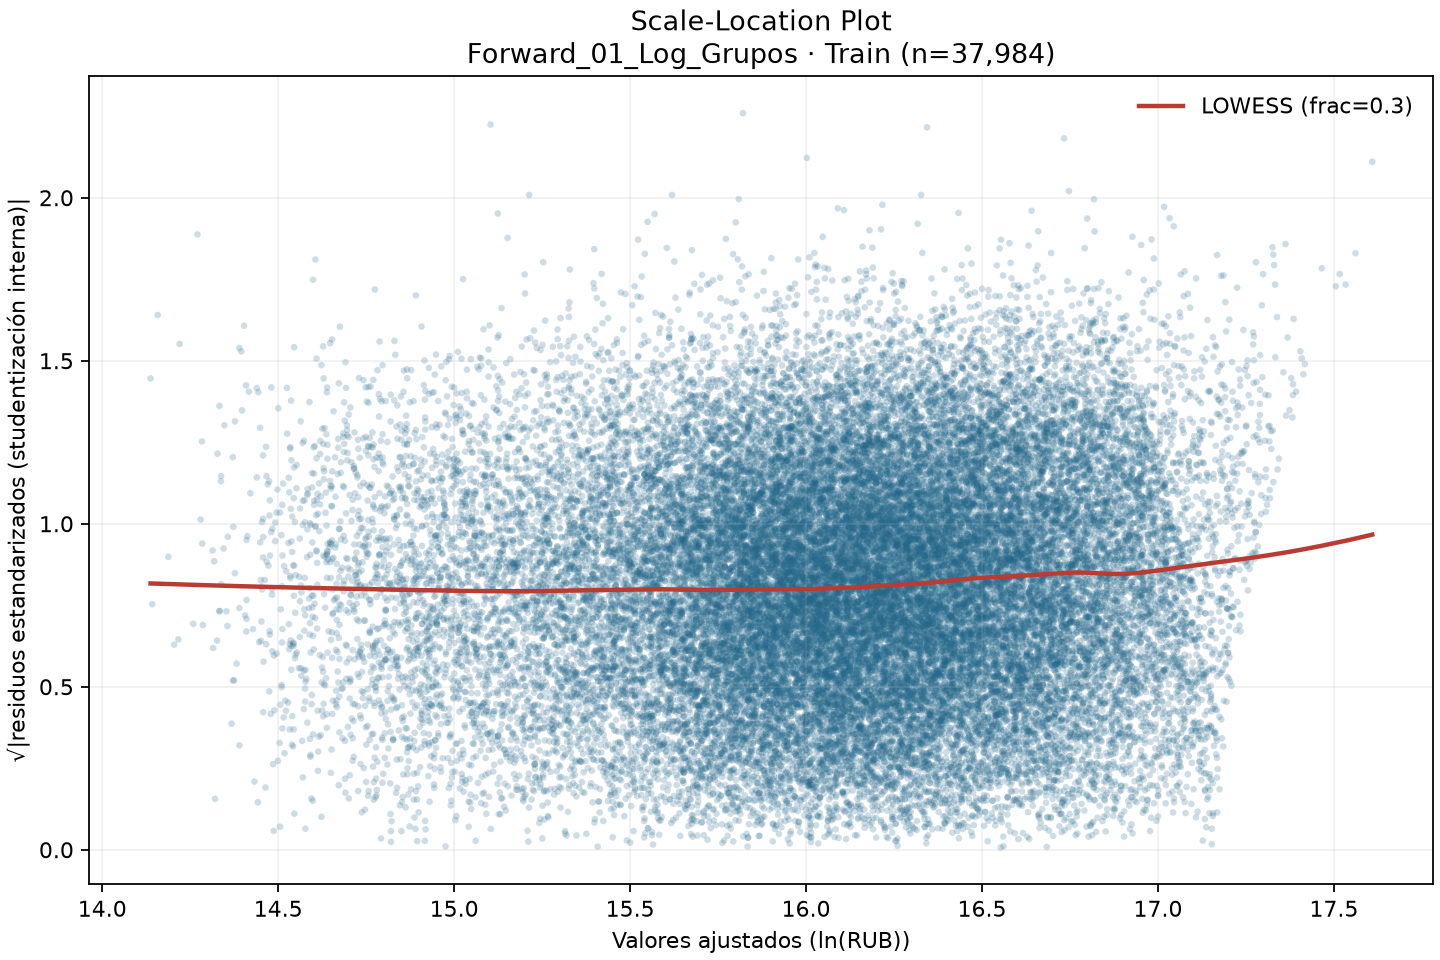

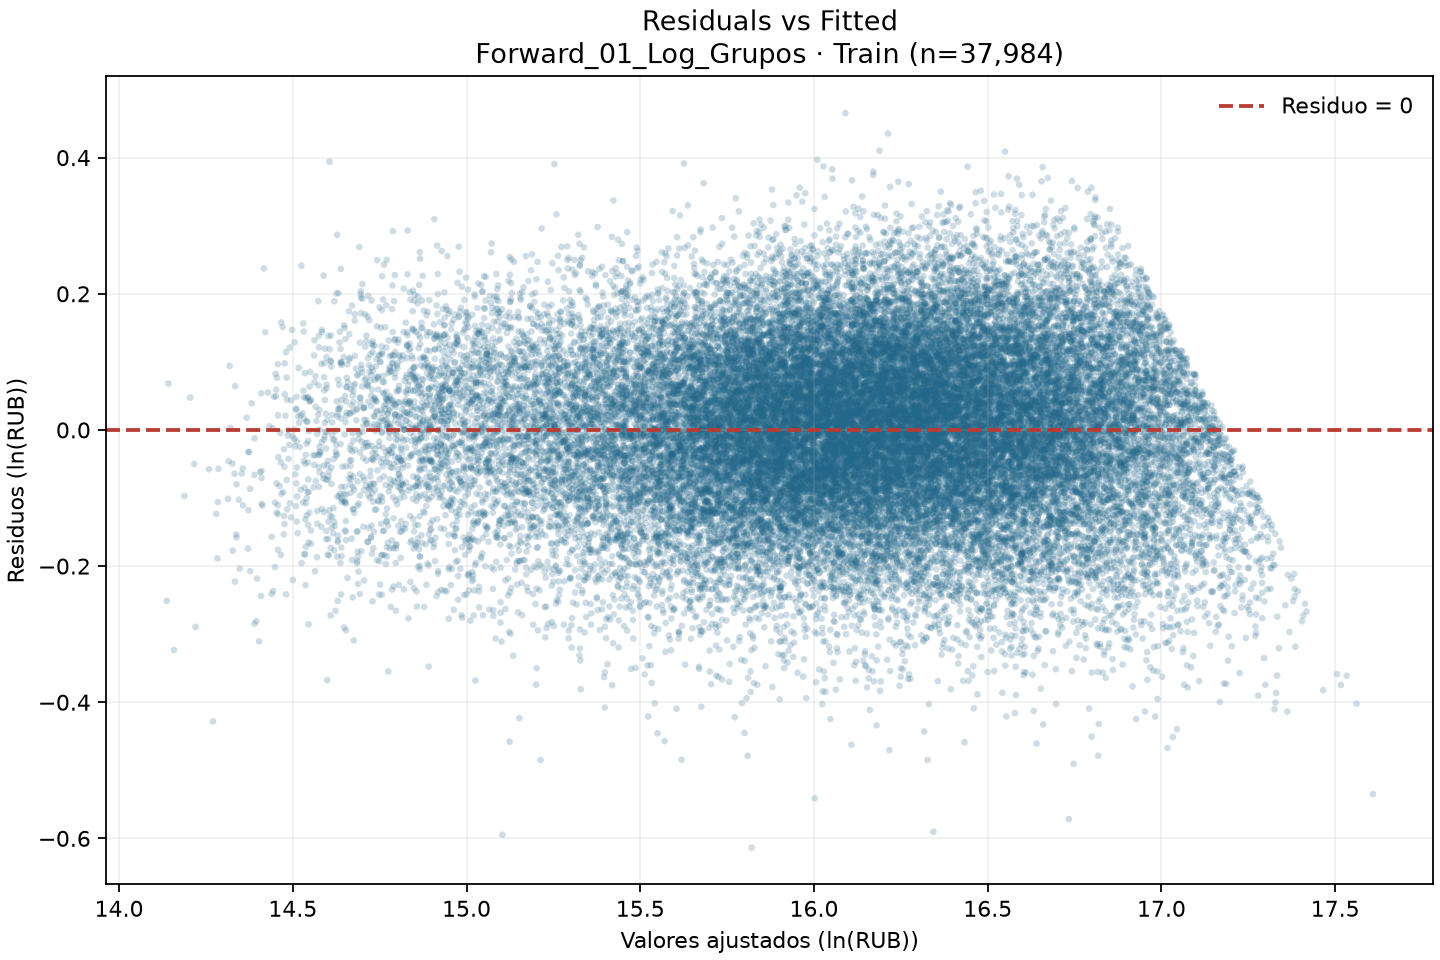

In [7]:
with sesion.paso():
    for nombre in ARCHIVOS:
        display(Image(filename=str(out / 'diagnosticos_residuales' / nombre)))


## 8. Importancia de las características
Calcular cinco permutaciones conjuntas por grupo sobre la validación fija, con semilla 42 y un único ajuste OLS interno. La importancia es `100 × (RMSE permutado − RMSE original) / RMSE original`.

Son importancias descriptivas sobre la partición utilizada para seleccionar características; no constituyen una evaluación independiente ni efectos causales y pueden verse afectadas por la correlación entre predictores.

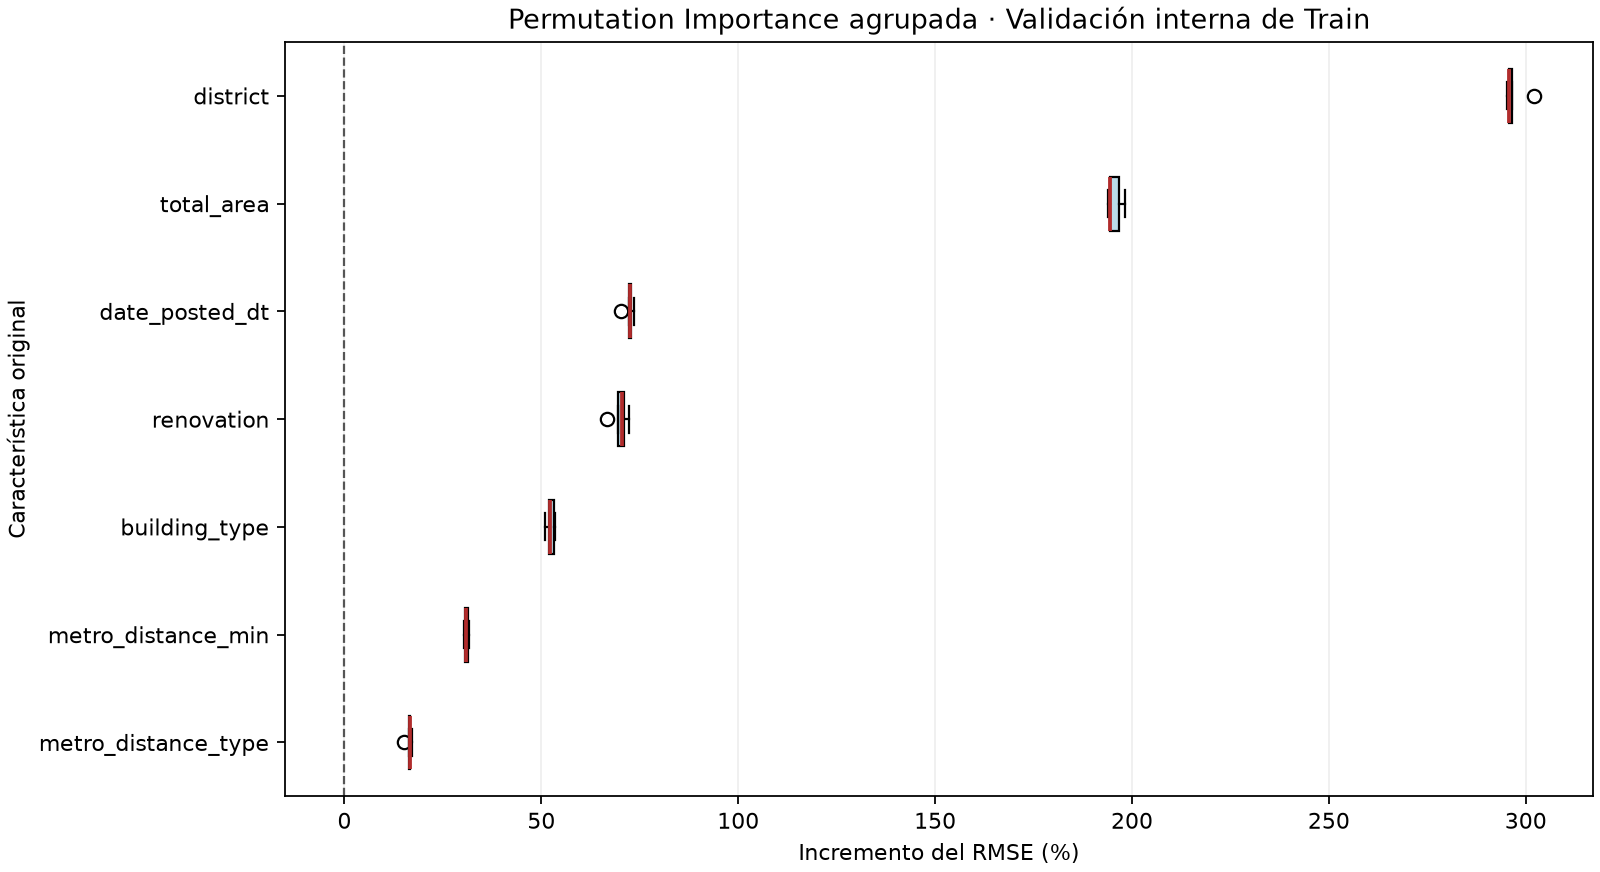

In [8]:
with sesion.paso():
    importancias = s.importancia_permutacion_grupos(X, y, grupos, seleccionadas, fit, val,
        n_repeticiones=5, random_state=42,
        rmse_esperado=metricas['selection_rmse_validation_original'])
    importancias.to_csv(out / 'importancia_caracteristicas.csv', index=False)
    s.guardar_boxplot_importancia(importancias, out / 'importancia_caracteristicas_boxplot.png')
    b.guardar_json(out / 'importancia_metodologia.json', {
        'metodo': 'Permutation Importance agrupada', 'n_repeticiones': 5, 'random_state': 42,
        'formula': '100 * (RMSE permutado - RMSE original) / RMSE original',
        'evaluacion': 'validación interna de Train utilizada en selección; descriptiva',
        'modelo_importancia': 'OLS ajustado una vez en entrenamiento interno; exp sin corrección',
        'forward_run_id': forward['run_id'], 'dataset_sha256': contexto_train['dataset_sha256'],
        'particion_sha256': b.sha256(out / 'particion_interna.npz'),
        'modelo_final_sha256': b.sha256(out / 'modelo_statsmodels.pkl')})
    display(Image(filename=str(out / 'importancia_caracteristicas_boxplot.png')))


## 9. Registro en DagsHub/MLflow
Agregar la tabla de características, el Box Plot y los valores por repetición al mismo Run `Forward_01_Log_Grupos`; verificar los archivos registrados y conservar las métricas y el modelo existentes.

In [9]:
%%capture
with sesion.paso():
    s.registrar_presentacion(cliente, forward, out, [
        'caracteristicas_seleccionadas.md', 'importancia_caracteristicas_boxplot.png',
        'importancia_caracteristicas.csv', 'importancia_metodologia.json'])
    assert b.sha256(out / 'modelo_statsmodels.pkl') == json.loads(
        (out / 'importancia_metodologia.json').read_text(encoding='utf-8'))['modelo_final_sha256']


In [10]:
with sesion.paso():
    url = f"{b.TRACKING_URI}/#/experiments/{forward['experiment_id']}/runs/{forward['run_id']}"
    display(Markdown(f"[{s.NOMBRE_RUN}]({url}) — **FINISHED**. Resumen, importancias, métricas, diagnósticos y modelo verificados."))


[Forward_01_Log_Grupos](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/d43e88406b0843c5b7963d2c1e62d15a) — **FINISHED**. Resumen, importancias, métricas, diagnósticos y modelo verificados.

# Experimento 02 — Group Lasso + OLS

## 1. Configuración del experimento
Reutilizar Train, los grupos y la partición interna de Forward. Recuperar desde MLflow la referencia `Forward_01_Log_Grupos`, con las mismas escalas y observaciones.

In [1]:
%%capture
with sesion.paso():
    from scripts import group_lasso_ols as gl
    referencia_02 = s.recuperar_experimento(cliente, nombre=s.NOMBRE_RUN, run_id=forward['run_id'],
        parametros={'target_transform': 'ln(Target)', 'inverse_transform': 'exp',
            'bias_correction': 'none', 'train_fraction': '1.0', 'n_train': len(y),
            'intercepto': 'True', 'excluded_predictors': ','.join(s.EXCLUIDAS),
            'aic_bic_convention': 'statsmodels_gaussian_log_RUB_k_rank'},
        etiquetas={'dataset_sha256': contexto_train['dataset_sha256']})
    config_02 = dict(gl.CONFIG)
    lambdas_02 = None  # Por defecto: 40 valores entre lambda_max y 0,001 × lambda_max.
    salida_02 = sesion.carpeta('group_lasso')
    salida_02.mkdir(exist_ok=True)
    with np.load(out / 'particion_interna.npz') as particion_forward:
        assert np.array_equal(fit, particion_forward['fit'])
        assert np.array_equal(val, particion_forward['validation'])
    assert grupos == estado['grupos_caracteristicas']['grupos']


## 2. Selección de características mediante Group Lasso
Estandarizar solo con el entrenamiento interno y aplicar penalización `lambda × Σ √p_g ‖β_g‖₂`, con intercepto sin penalizar. Evaluar toda la grilla, descartar más de 12 grupos y comparar los mejores subconjuntos por complejidad con mejora mínima del 0,5 %; un rechazo no detiene la búsqueda.

Los RMSE corresponden a OLS provisionales y precios originales mediante `exp`. La implementación y la convención del objetivo se documentan en los artefactos, siguiendo la [formulación de Group Lasso](https://group-lasso.readthedocs.io/en/latest/maths.html).

In [2]:
%%capture
with sesion.paso():
    seleccion_02 = gl.buscar_group_lasso(X, y, grupos, fit, val, salida_02,
        lambdas=lambdas_02, config=config_02)
    b.guardar_json(salida_02 / 'comparabilidad.json', {
        'reference_run_id': referencia_02['run_id'], 'dataset_sha256': contexto_train['dataset_sha256'],
        'particion_forward_sha256': b.sha256(out / 'particion_interna.npz'),
        'indices_internos_identicos': True, 'target': 'ln(Target)', 'inversa': 'exp sin corrección',
        'aic_bic': 'statsmodels_gaussian_log_RUB_k_rank',
        'comparacion': 'mismas filas de Train; métricas de validación separadas'})


## 3. Entrenamiento del OLS definitivo
Ajustar una sola vez sobre el 100 % de Train, con intercepto y todos los predictores de cada grupo seleccionado. Utilizar las columnas transformadas existentes sin escalado adicional ni nuevas eliminaciones.

In [3]:
%%capture
with sesion.paso():
    resultado_02 = gl.entrenar_exportar(base, X, y, grupos, seleccion_02,
        contexto_train, referencia_02, salida_02)


## 4. Características originales seleccionadas
Mostrar únicamente las características originales y sus cantidades de predictores, excluyendo el intercepto.

In [4]:
with sesion.paso():
    display(Markdown(resultado_02['caracteristicas_md']))


| Característica seleccionada | Cantidad de predictores |
|---|---|
| `total_area` | 1 |
| `ceiling_height` | 1 |
| `metro_distance_min` | 1 |
| `metro_to_center_km` | 1 |
| `surface_corrected` | 1 |
| `has_balcony` | 1 |
| `metro_distance_type` | 1 |
| `building_type` | 5 |
| `renovation` | 3 |
| `district` | 128 |
| `date_posted_dt` | 1 |
| Total: 11 características | 144 predictores |

## 5. Tabla comparativa de métricas
Comparar con las métricas de Forward recuperadas desde MLflow. `Δ = GroupLasso_02_Log_Grupos_OLS − Forward_01_Log_Grupos`; conservar separadas las escalas y el RMSE de validación interna.

In [5]:
with sesion.paso():
    display(Markdown(resultado_02['comparacion_md']))


| Métrica | Forward_01_Log_Grupos | GroupLasso_02_Log_Grupos_OLS | Δ |
|---|---|---|---|
| R² (ln(RUB)) | 0.9535767773806381 | 0.9547646387878368 | 0.0011878614071987315 |
| R² ajustado (ln(RUB)) | 0.9534050348875294 | 0.954592491214842 | 0.0011874563273126526 |
| MAE (ln(RUB)) | 0.09548260169146015 | 0.09426428805934255 | -0.001218313632117607 |
| RMSE (ln(RUB)) | 0.1201788710987355 | 0.1186313599051369 | -0.001547511193598597 |
| RSS (ln(RUB)) | 548.6014328485893 | 534.5640086189536 | -14.03742422963569 |
| MSE (ln(RUB)) | 0.014442961058566484 | 0.014073399552942123 | -0.000369561505624361 |
| AIC (ln(RUB)) | -52883.10480890103 | -53859.67716519779 | -976.5723562967614 |
| BIC (ln(RUB)) | -51678.27104696631 | -52620.66372207343 | -942.3926751071194 |
| F-statistic (ln(RUB)) | 5552.363658639613 | 5546.198660706601 | -6.164997933012273 |
| Probabilidad F-statistic (ln(RUB)) | 0.0 | 0.0 | 0.0 |
| n_obs | 37984.0 | 37984.0 | 0.0 |
| Cantidad de predictores | 140.0 | 144.0 | 4.0 |
| n_parameters_effective | 141.0 | 145.0 | 4.0 |
| n_coefficients | 141.0 | 145.0 | 4.0 |
| df_model | 140.0 | 144.0 | 4.0 |
| df_resid | 37843.0 | 37839.0 | -4.0 |
| log_likelihood (ln(RUB)) | 26582.552404450515 | 27074.838582598895 | 492.2861781483807 |
| Durbin-Watson (ln(RUB)) | 1.7997379301297685 | 1.797299334433014 | -0.002438595696754531 |
| n_coefficients_p_gt_005 (ln(RUB)) | 4.0 | 3.0 | -1.0 |
| n_coefficients_p_undefined (ln(RUB)) | 0.0 | 0.0 | 0.0 |
| Condition Number | 13160.606929511569 | 13237.46125929748 | 76.85432978591234 |
| rank_deficiency | 0.0 | 0.0 | 0.0 |
| jarque_bera (ln(RUB)) | 297.74674309965445 | 232.84382620488938 | -64.90291689476507 |
| jarque_bera_pvalue (ln(RUB)) | 2.2136870964588015e-65 | 2.7453996058051007e-51 | 2.745399605805079e-51 |
| skewness (ln(RUB)) | -0.20221783738082585 | -0.1862383447440699 | 0.015979492636755965 |
| kurtosis (ln(RUB)) | 3.1567213199003024 | 3.0915550119543442 | -0.06516630794595812 |
| omnibus (ln(RUB)) | 287.57947982513156 | 228.23635062780846 | -59.343129197323094 |
| omnibus_pvalue (ln(RUB)) | 3.57198315107597e-63 | 2.7485660403207126e-50 | 2.7485660403203556e-50 |
| VIF máximo | 8.553944860139906 | 10.369011857965393 | 1.8150669978254879 |
| VIF promedio | 2.031640323596522 | 2.0461371514526863 | 0.014496827856164352 |
| Cantidad VIF > 5 | 1.0 | 1.0 | 0.0 |
| Cantidad VIF > 10 | 0.0 | 1.0 | 1.0 |
| vif_infinite_count | 0.0 | 0.0 | 0.0 |
| vif_undefined_count | 0.0 | 0.0 | 0.0 |
| bp_lm (ln(RUB)) | 768.1881354835621 | 939.087999763404 | 170.89986427984195 |
| bp_lm_pvalue (ln(RUB)) | 2.336959491146487e-87 | 8.128164586090668e-117 | -2.336959491146487e-87 |
| bp_f (ln(RUB)) | 5.579530035116568 | 6.661236940435628 | 1.0817069053190593 |
| bp_f_pvalue (ln(RUB)) | 1.6853410264462636e-88 | 1.1861761817430169e-118 | -1.6853410264462636e-88 |
| R² (precio original) | 0.9243969318325274 | 0.9259444802303901 | 0.0015475483978627524 |
| R² ajustado (precio original) | 0.9241172386384506 | 0.9256626547369357 | 0.0015454160984850196 |
| MAE (precio original) | 1116830.7647747274 | 1104234.8410111216 | -12595.923763605766 |
| RMSE (precio original) | 1609441.4455567568 | 1592884.1387621781 | -16557.306794578675 |
| MAPE (precio original) | 9.633475459651416 | 9.506588740738916 | -0.12688671891250003 |
| RSS (precio original) | 9.839002230541446e+16 | 9.637603894369246e+16 | -2013983361722000.0 |
| MSE (precio original) | 2590301766675.823 | 2537279879520.126 | -53021887155.697266 |
| Cantidad de características | 7.0 | 11.0 | 4.0 |

## 6. Diagnóstico gráfico de residuos
Mostrar QQ-Plot, Scale-Location y Residuals vs Fitted del OLS definitivo, en escala logarítmica.

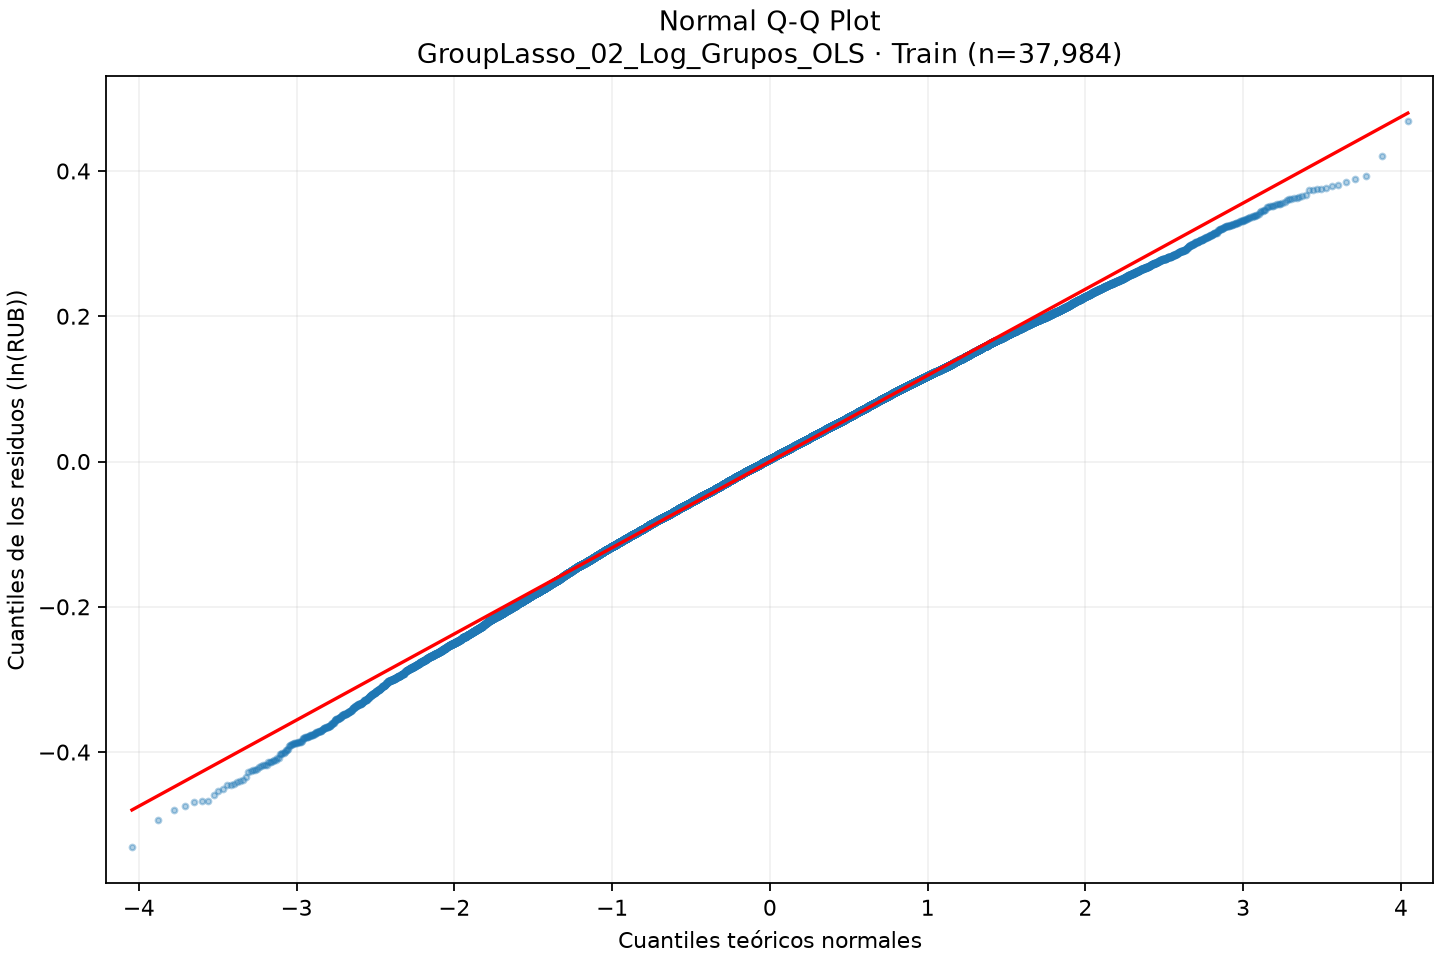

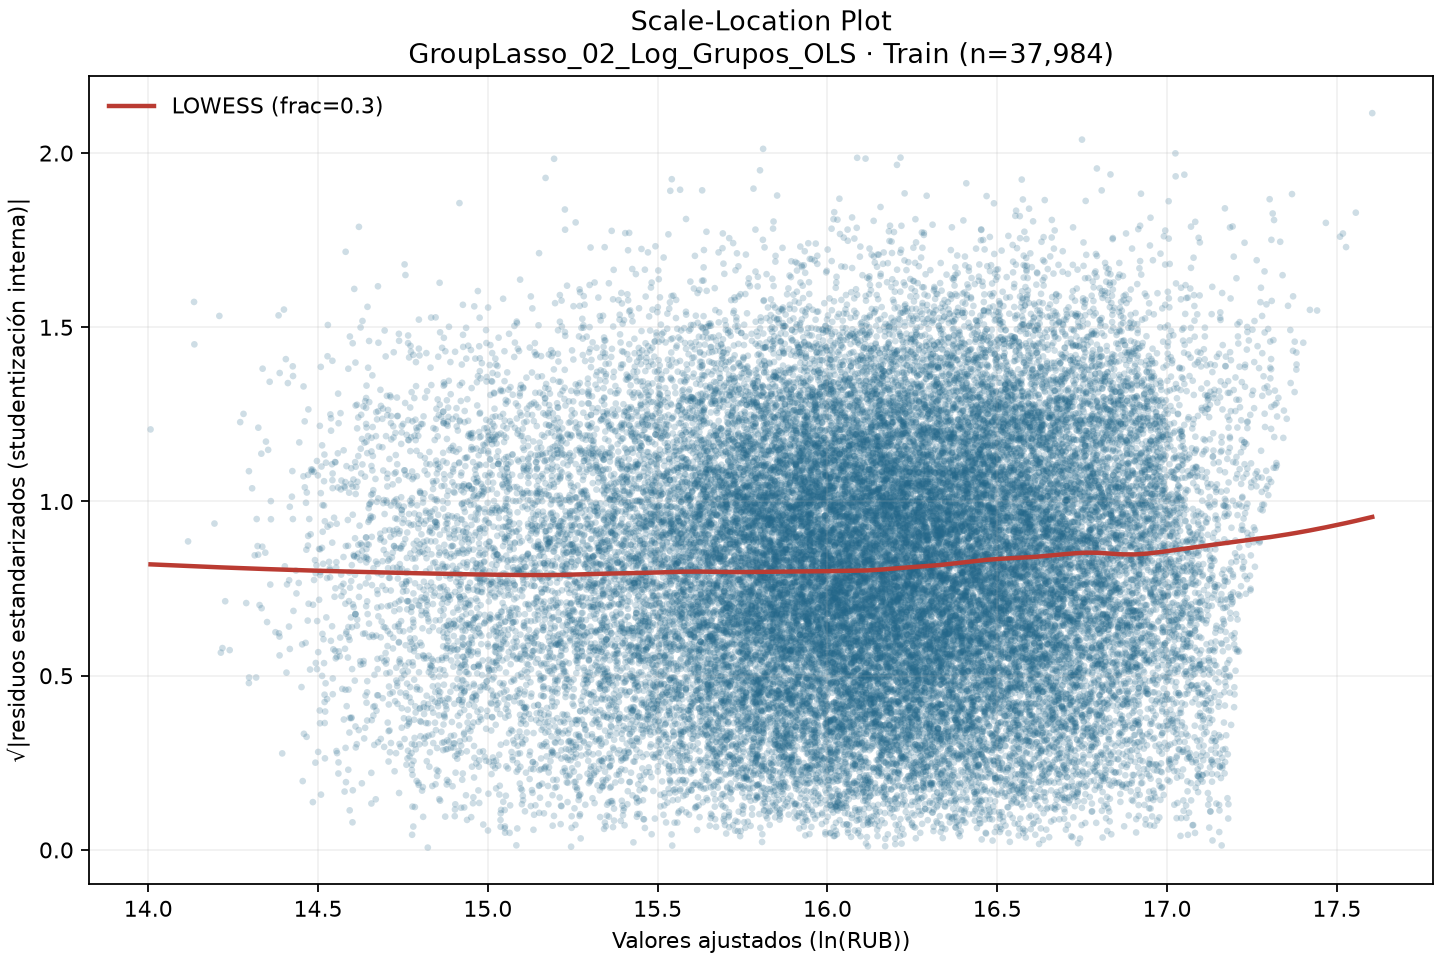

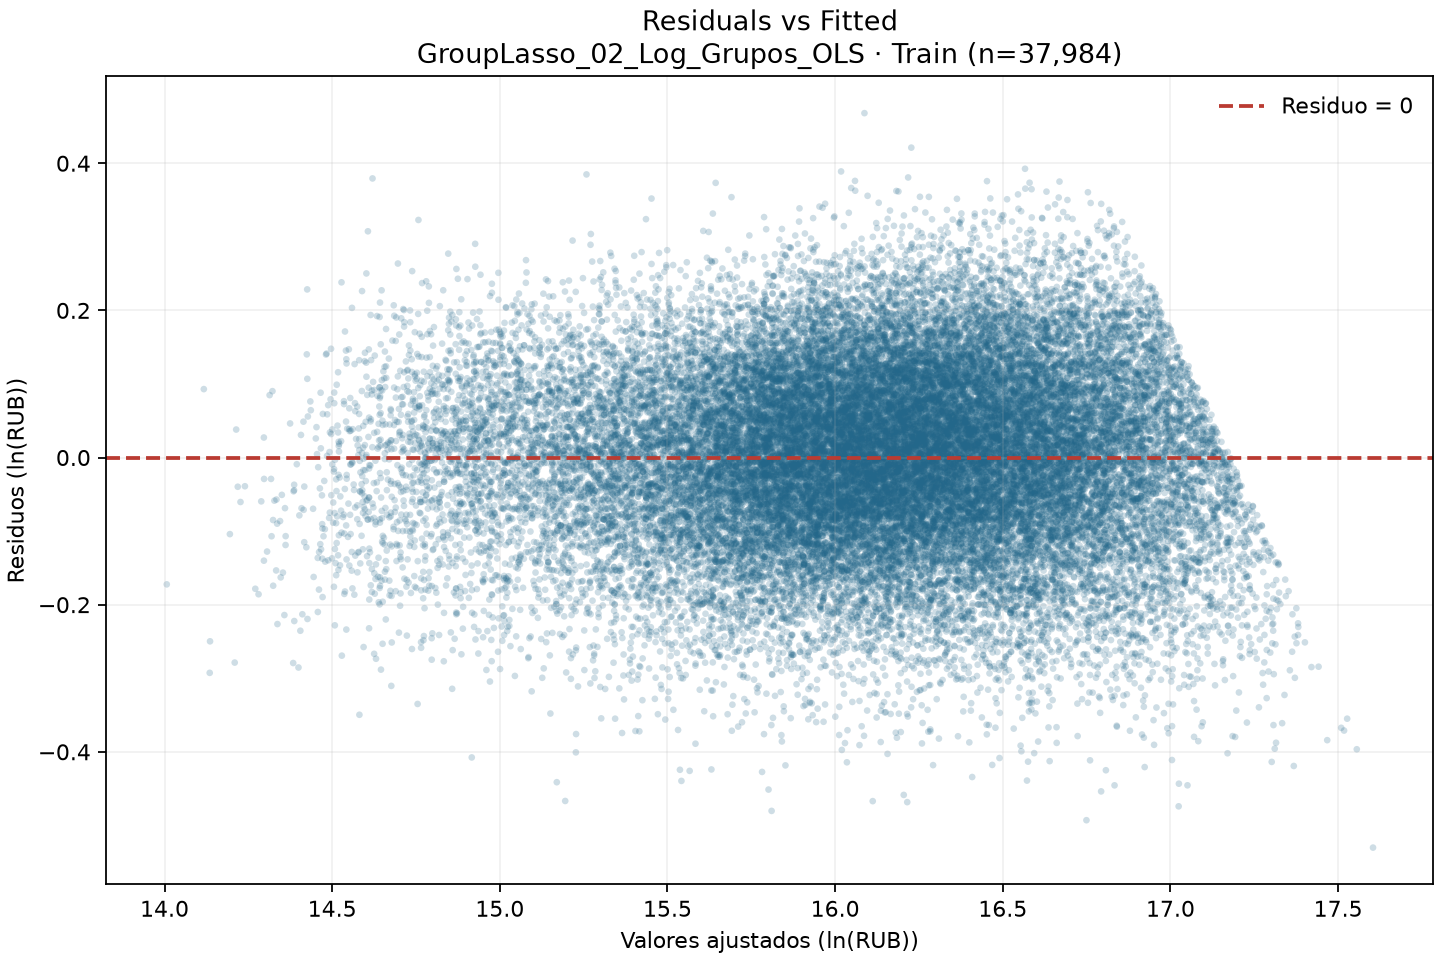

In [6]:
with sesion.paso():
    for nombre in ARCHIVOS:
        display(Image(filename=str(salida_02 / 'diagnosticos_residuales' / nombre)))


## 7. Box Plot de importancia agrupada
Realizar diez permutaciones conjuntas por característica, con semilla 42, sobre un único OLS provisional en la partición fija. Mostrar `100 × (RMSE permutado − RMSE original) / RMSE original`, ordenado por mediana. Estas importancias son descriptivas porque reutilizan la validación de selección.

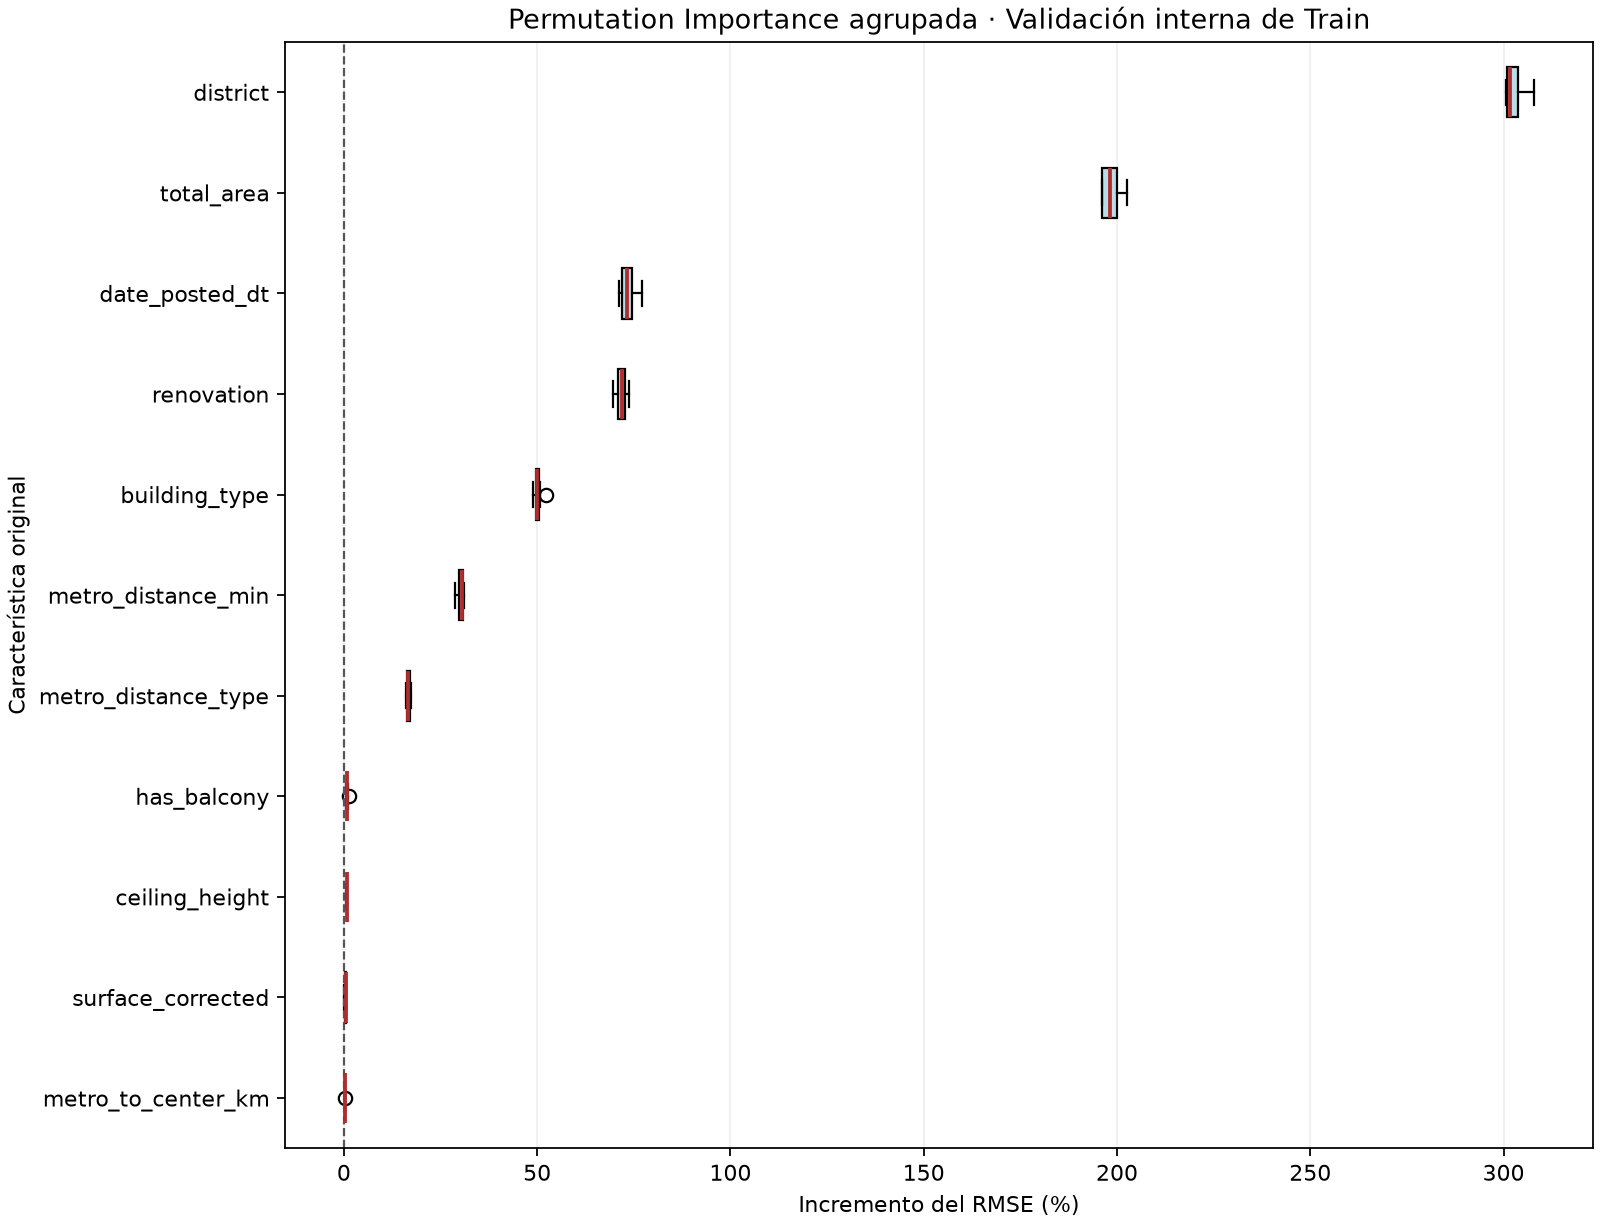

In [7]:
with sesion.paso():
    importancias_02 = s.importancia_permutacion_grupos(X, y, grupos, seleccion_02['seleccionadas'],
        fit, val, n_repeticiones=10, random_state=42,
        rmse_esperado=seleccion_02['rmse_validation_original'])
    importancias_02.to_csv(salida_02 / 'importancia_caracteristicas.csv', index=False)
    s.guardar_boxplot_importancia(importancias_02, salida_02 / 'importancia_caracteristicas_boxplot.png')
    b.guardar_json(salida_02 / 'importancia_metodologia.json', {
        'metodo': 'Permutation Importance agrupada', 'n_repeticiones': 10, 'random_state': 42,
        'evaluacion': 'validación interna de Train; descriptiva, utilizada en selección',
        'formula': '100 * (RMSE permutado - RMSE original) / RMSE original',
        'rmse_referencia': seleccion_02['rmse_validation_original'],
        'reference_run_id': referencia_02['run_id'], 'dataset_sha256': contexto_train['dataset_sha256']})
    display(Image(filename=str(salida_02 / 'importancia_caracteristicas_boxplot.png')))


## 8. Registro en DagsHub/MLflow
Registrar `GroupLasso_02_Log_Grupos_OLS` dentro del experimento existente, con el historial de regularización, el modelo OLS, las tablas, los cuatro gráficos y la referencia al Run Forward. Verificar la integridad de los artefactos registrados.

In [8]:
%%capture
with sesion.paso():
    registro_02 = gl.registrar(cliente, resultado_02, seleccion_02, referencia_02)


In [9]:
with sesion.paso():
    display(Markdown(f"[{gl.NOMBRE_RUN}]({registro_02['url']}) — **{registro_02['status']}**. "
        f"Run ID: `{registro_02['run_id']}`. Métricas, tablas, cuatro gráficos y modelo verificados."))

    sesion.cerrar()


[GroupLasso_02_Log_Grupos_OLS](https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/5/runs/ac9faf6b61db4a7f8e274553199c5658) — **FINISHED**. Run ID: `ac9faf6b61db4a7f8e274553199c5658`. Métricas, tablas, cuatro gráficos y modelo verificados.